# 3D-XRT: 3D analysis of X-ray Swift-XRT (PC) data using gammapy

This notebook provides a tutorial on the 3D-XRT analysis method, to perform a 3D (X,Y,E) analysis of X-ray data using the gammapy gamma-ray analysis tool.
While at gamma-ray energies (due to moderate PSF), most sources can be represented by simple analytical functions (points, Gaussian, disks) this is less common in X-rays due to arcsec PSFs.  

Here we test the 3D-XRT analysis on a simple point-like AGN target (composite Mrk876) without pile-up.  

Refs:
- First 3D Analysis of Swift X-ray Observations with Complex Pile-up: A Novel \texttt{gammapy} Application to NGC~1275 (Review in progress)

## Data

The observation is question is an unusually long test observation, and can therefore be computationally heavy.
The data in this tutorial is downloaded from https://www.swift.ac.uk/swift_portal/
The xrt instrument Locally-reprocessed data (HEASoft v6.35.2) for the Target ID 00050300 was downloaded with:

wget -e 'robots=off' -nv -w 2 -nh --cut-dirs=1 -r --no-parent --reject "index.html*" https://www.swift.ac.uk/archive/reproc/00050300004/xrt/

For excluding nearby sources, source files obtained for the observation from https://www.swift.ac.uk/user_objects/tprods/USERPROD_282534/ is used

The full enclosure ARF required was creating by saving a suitable circle region that envelops the desired image region to a file and with heasoft (v6.36) run the bash file included in the tutorial data directory:

./run_arfcreation.sh 00050300004

Note: CALDB recommended rmf and psf files will be given in chatter

In [ ]:
%matplotlib inline
import sys,glob,os
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import matplotlib.colors as colors

import numpy as np

from astropy import wcs
from astropy.io import fits, ascii
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.visualization.wcsaxes import SphericalCircle
from astropy.table import Table

from regions import CircleSkyRegion, CircleAnnulusSkyRegion

This tutorial was developed using gammapy dev, but gammapy 2.1 should be similar

In [ ]:
import gammapy
gammapy.__version__
#gammapy.__path__

'2.0.dev4285+g07efacb31'

In [ ]:
from gammapy.estimators import FluxPointsEstimator
from gammapy.irf import EDispKernel,EDispKernelMap
from gammapy.maps import WcsGeom, MapAxis, MapAxes, WcsNDMap, Map, RegionGeom
from gammapy.modeling.models import Models, PowerLawSpectralModel, PowerLawNormSpectralModel, TemplateSpectralModel, PointSpatialModel, SkyModel, GaussianSpectralModel
from gammapy.modeling.models.spatial import TemplateSpatialModel, ConstantSpatialModel
from gammapy.makers.utils import make_psf_map
from gammapy.utils.scripts import make_path
from gammapy.utils.regions import make_concentric_annulus_sky_regions
from gammapy.datasets.io import OGIPDatasetReader
from gammapy.datasets import MapDataset
from gammapy.data import GTI
from gammapy.modeling import Fit


from gammapy_mwl.models.hydrogen import (
    generate_tbabs_interp_table,
    get_tbabs_template_model,
)
import requests

## Define paths, source, observation data

In [ ]:
# set working directory manaully or automatically
# repbase = Path('')
repbase = Path(os.getcwd())

data_path = repbase / "data"
out_path = repbase / "output"
# plot_path = repbase / "plots"

data_path.mkdir(exist_ok=True, parents=True)
out_path.mkdir(exist_ok=True, parents=True)
# plot_path.mkdir(exist_ok=True, parents=True)

In [ ]:
# PSF function (CALDB XRT PC psf parameter file included in directory)
psf_dir = os.path.abspath(repbase / 'psf')
sys.path.append(psf_dir)
from SwiftPSF_updated_v3 import SwiftPSF

In [ ]:
obj_name = 'Mrk876'
redshift = 0.129 # from simbad 0.12917394
obj_pos = SkyCoord.from_name(obj_name)
print(f"Source is {obj_name} at z={redshift}, RA={obj_pos.ra}, dec={obj_pos.dec}")

Source is Mrk876 at z=0.129, RA=243.48824793 deg, dec=65.7194313 deg


In [ ]:
#DATA definition

inst='XRT'

obslist=['00050300004'] 

evtdir= data_path / f"reproc"
rmf_file = data_path / "swxpc0to12s0_20010101v012.rmf" # CALDB recommended rmf file for this observation
psffile = f"{psf_dir}/swxpsf20010101v006.fits" # CALDB recommended psf file
arffile_list = []
for obs in obslist:
    arffile_list.append(f"{evtdir}/{obs}/xrt/mine/Obs_{obs}pc_all_602.arf") # created full enclosure arf file
arffile_first=arffile_list[0]

userprod=282534
sources_total_file = data_path / f"USERPROD_{userprod}/sourceDet/sources_total.list"

print(f"Source is {obj_name} at z={redshift}, RA={obj_pos.ra}, dec={obj_pos.dec}")

number=0 # if only choosing response files from one

center=obj_pos
radius = 425
width = (2*radius*u.arcsec).to('deg') # 425 arcsec is background region radius, so 2*425 arcsec is the diameter of the region needed
print("width:", width)

# Search pattern
evtfile='sw*xpcw4po_cl.evt.gz' # if looking for observations with other window sizes use evtfile='sw*xpc**cl.evt.gz'
vigfile='sw*xpcw4po_vignet_ex.img.gz'
exfile='sw*xpcw4po_ex.img.gz'

inst_dict={'MOS': {'pix_size':4.1*u.arcsec},
           'PN': {'pix_size':4.1*u.arcsec},
           'ACIS':{'pix_size':0.492*u.arcsec},
           'HRC':{'pix_size':0.492*u.arcsec},
           'XIFU':{'pix_size':4*u.arcsec},
           'eROSITA':{'pix_size':4*u.arcsec},
           'XRT':{'pix_size':2.357*u.arcsec}}

myinst=inst_dict[inst]

Source is Mrk876 at z=0.129, RA=243.48824793 deg, dec=65.7194313 deg
width: 0.2361111111111111 deg


In [ ]:
label = f"3D-XRT_{obj_name}_r{radius:.0f}"
for obs in obslist:
    print(obs)
    label += f"_{obs}"
label

00050300004


'3D-XRT_Mrk876_r425_00050300004'

In [ ]:
tolm = [
    '#CC6677', #rose
    '#332288', #indigo
    '#DDCC77', #sand
    '#117733', #green
    '#88CCEE', #cyan
    '#882255', #wine
    '#44AA99', #teal
    '#999933', #olive
    '#AA4499', #purple
    '#DDDDDD', #pale grey
    ]

gammapy_colour = tolm[1]
gammapy_alpha = 0.5
onoff_colour = tolm[3]
onoff_alpha = 0.5
onoff_line_alpha = 1
trad_colour = tolm[0]
trad_alpha = 0.5
trad_line_alpha = 1

shade_colour = tolm[-1]

## 1. Create Counts Cube File

This section could be done separate to the rest of the analysis

Find and read from the Swift-XRT cleaned event file, binning each event by RA, Dec sky position (from detector $X, Y$ coordinates) and energy channel (PI\times10).

The conversion of the Swift native format to \texttt{gammapy} format is achieved via the OGIP-compatible energy redistribution matrix (RMF). By reading in the relevant Swift-XRT RMF in \texttt{gammapy}, the reconstructed energy $E_{\rm reco}$ and true energy $E_{\rm true}$ axes required for analysis are defined from the Pulse Invariant (PI) detector channels and photon energy bins.

The counts cube is then created from that geometry as a \texttt{WcsNDMap}$(X_{\rm reco}, Y_{\rm reco}, E_{\rm reco})$, and filled with the event file data, binned by RA, Dec sky position (from detector $X, Y$ coordinates) and energy channel (PI$\times10$).

### EVT file functions

In [ ]:
plt.rcParams['image.origin'] = 'lower'
plt.rcParams['image.interpolation'] = 'nearest'

    

def getevt(evtdir,obs,evtfile='*evt2.*',inst='ACIS'):
    """
    Read an event file in a given directory using a evtfile filename pattern.
    Based on a skycoordinate column name (like X,Y) transform this in a RA, DEC array.
    The header from the event file is used for this transformation by building
    a WCS header using the hdrfromevt() function.
    Input:
     evtdir,obs: observation paths
     evtfile: evtfile regexp pattern
     inst: instrument name ('MOS','PN','ACIS','HRC','eROSITA')
    Returns:
     RA, DEC, E, TOA : numpy arrays
    """

    if inst in ['ACIS','HRC']:
        regexp='%s/%s/*/%s'%(evtdir,obs,evtfile)
    if inst in ['eROSITA']:
        regexp='%s/%s/%s'%(evtdir,obs,evtfile)
    if inst in ['MOS','PN']:
        regexp='%s/%s/pps_old/%s'%(evtdir,obs,evtfile)
    if inst in ['XRT']:
        regexp='%s/%s/xrt/event/%s'%(evtdir,obs,evtfile)
    
    print('Search expression: \n ',regexp)
    for myfile in glob.glob(regexp):
        file_evt=myfile
    
    print('Reading file :',file_evt)
    hdr = fits.getheader(file_evt, extname='EVENTS')
    hdus = fits.open(file_evt)
    evt = hdus[1].data 

    
    try:
        TOA = evt['TIME']
    except:
        print('Time column not found. Returnin empty array')
        TOA = np.zeros_like(Xevt)
    

    if inst in ['MOS','PN','ACIS', 'XRT']:
        
        Xevt = evt['X']
        Yevt = evt['Y']
        hdr2 = hdrfromevt(hdr,'x', 'y')
        print('Skyprojection to RA, DEC')    
        w = wcs.WCS(hdr2)
        RA, DEC = w.wcs_pix2world(Xevt, Yevt, 1)

    elif inst == 'eROSITA':
        RA, DEC = evt['RA'], evt['DEC']
        
    if inst in ['MOS','PN','ACIS','eROSITA','XRT']:
        if inst in ['MOS', 'PN', 'eROSITA']:
            E = evt['PI']
        elif inst == 'ACIS':
            E = evt['energy']
        elif inst == 'XRT':
            E = evt['PI']*10

        print('%s events loaded '%(len(RA)) )
        return RA, DEC, E, TOA, hdr
    else:
        print('%s events loaded '%(len(RA)) )
        return RA, DEC, TOA, hdr        

    
def hdrfromevt(hdr,col1,col2):
    """
    Read an XMM event list and get the corresponding keywords
    for column col1,col2 (e.g. X,Y)
    then creates a standard header with CRVAL, CRPIX, etc
    instead of TCRPX6, TCDLT6, etc
    Search for values RA- in TCTYP* keywords in header:
    Input:
     hdr: the header from the event file
     col1,col2: str, the name of the column containing the sky coordinates.
    Return:
     a standard WCS header
    """
    #Get the number of the column containing the X, Y columns
    colvals=hdr.values()
    mystring='RA-'
    for key, value in hdr.items():
        if 'TCTYP' in key:
            if 'RA--' in value:
                Xcolnum=int(key.split('TCTYP')[-1])
    Ycolnum=Xcolnum + 1
    # Create a new WCS object from the keywords corresponding to the column X,Y
    Xcolnum=str(Xcolnum) ; Ycolnum=str(Ycolnum)

    w = wcs.WCS(naxis=2)
    w.wcs.crpix = [hdr['TCRPX'+Xcolnum], hdr['TCRPX'+Ycolnum]]
    w.wcs.cdelt = [hdr['TCDLT'+Xcolnum], hdr['TCDLT'+Ycolnum]]
    w.wcs.crval = [hdr['TCRVL'+Xcolnum], hdr['TCRVL'+Ycolnum]]
    w.wcs.ctype = [hdr['TCTYP'+Xcolnum], hdr['TCTYP'+Ycolnum]]

    # write the HDU object WITH THE HEADER
    hdr2 = w.to_header()
    return hdr2

### Looping and stacking on the list of observations

In [ ]:
#%%time

RA=np.array([])
DEC=np.array([])
E=np.array([])
TOA=np.array([])

mytype='float32'

exptime=0
Tstart=0

print(evtdir)

for obs in obslist:

    try :
        if inst in ['ACIS','MOS','PN','eROSITA','XRT']: RA_, DEC_, E_, TOA_, hdr = getevt(evtdir,obs,evtfile=evtfile,inst=inst)
    except:
        print(f'Observation {obs} not found')

    try:
        print('\n MET start time %0.f s'%(hdr['TSTART']))  
        print('corresponding to date %s \n'%(hdr['DATE-OBS'])) 
    except:
        continue

    try:
        print('Livetime = %.1f ks' %(hdr['LIVETIME']/1e3) )
        exptime+=hdr['LIVETIME']/1e3
    except:
        exptime=0
        
    if inst in ['ACIS','MOS','PN','eROSITA','XRT']:
        pos_=SkyCoord(RA_,DEC_,frame='fk5',unit="deg")
        sep=center.separation(pos_)
        mask = sep < np.sqrt(2)*width/2 # outer circle touching the box
        RAc, DECc, Ec, TOAc = RA_[np.nonzero(mask)], DEC_[np.nonzero(mask)], E_[np.nonzero(mask)], TOA_[np.nonzero(mask)]
    else:
        print('Instrument not in the list')

    print('ON: %s events kept \n'%(len(RAc)))
    print('Event rate = %.1f /s \n' %(len(RAc)/hdr['LIVETIME']) )
    RA=np.append(RA,RAc).astype(mytype)
    DEC=np.append(DEC,DECc).astype(mytype)
    E=np.append(E,Ec).astype(mytype)
    

      
print('Total Exposure time %1.f ks'%(exptime) )
print('Total events kept %e \n'%(len(RA)))



print('Done')
RA_=None ;RAc=None ; DEC_=None ;DECc=None ; E_=None ; Ec=None ; TOA_=None ; TOAc=None ; mask=None #freeing memory


radec=SkyCoord(RA,DEC,frame='fk5',unit="deg")
energy=E*u.eV
TOA = TOA*u.s


/Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/data/reproc
Search expression: 
  /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/data/reproc/00050300004/xrt/event/sw*xpcw4po_cl.evt.gz
Reading file : /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/data/reproc/00050300004/xrt/event/sw00050300004xpcw4po_cl.evt.gz
Skyprojection to RA, DEC
8055 events loaded 

 MET start time 131414699 s
corresponding to date 2005-03-02T00:06:03.2368 

Livetime = 25.5 ks
ON: 7448 events kept 

Event rate = 0.3 /s 

Total Exposure time 25 ks
Total events kept 7.448000e+03 

Done


In [ ]:
livetime = exptime * 1000
livetime

25457.32762715322

### Making a 3D histogram using gammapy WcsNDMap 

In [ ]:
%%time 

XYrebin = 1  # rebin of instrument native pixel size
Erebin = 7
ETrebin = 11
print(f"Using XYrebin {XYrebin} and Erebin {Erebin}")

try:
    rmf=EDispKernel.read(rmf_file) # works fine for swxpc0to12s6_20210101v016.rmf
    print("read in:", rmf_file)

except:
    # modify format F_CHAN and N_CHAN, needed for example for swxpc0to12s6_20130101v014.rmf
    rmffile = fits.open(rmf_file, memmap=False, checksum=True)
    print("read in:", rmf_file)
    matrix_hdu = rmffile['MATRIX']  # Access the MATRIX extension
    old_data = matrix_hdu.data
    old_header = matrix_hdu.header

    new_fchan = np.array([np.atleast_1d(x) for x in old_data['F_CHAN']], dtype=object)
    new_nchan = np.array([np.atleast_1d(x) for x in old_data['N_CHAN']], dtype=object)

    new_columns = []
    for col in matrix_hdu.columns:
        if col.name == 'F_CHAN':
            # 'PJ()' defines a variable-length array of 32-bit integers
            new_columns.append(fits.Column(name='F_CHAN', format='PJ()', array=new_fchan, unit=col.unit))
        elif col.name == 'N_CHAN':
            new_columns.append(fits.Column(name='N_CHAN', format='PJ()', array=new_nchan, unit=col.unit))
        else:
            # Keep other columns (like ENERG_LO, ENERG_HI, MATRIX) as they are
            new_columns.append(col)

    new_matrix_hdu = fits.BinTableHDU.from_columns(new_columns, header=old_header)
    rmffile['MATRIX'] = new_matrix_hdu
    mod_rmf_file = f"{evtdir}/{obslist[0]}/xrt/mine/modified_Obs_{obslist[number]}pc.rmf"
    rmffile.writeto(mod_rmf_file, overwrite=True, checksum=True)
    print("written to:", mod_rmf_file)
    rmffile.close()
    print(f"Modified RMF saved to {mod_rmf_file}")

    rmf=EDispKernel.read(mod_rmf_file)

print('pre-sliced rmf', rmf)

Using XYrebin 1 and Erebin 7
read in: /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/data/swxpc0to12s0_20010101v012.rmf
written to: /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/data/reproc/00050300004/xrt/mine/modified_Obs_00050300004pc.rmf
Modified RMF saved to /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/data/reproc/00050300004/xrt/mine/modified_Obs_00050300004pc.rmf
pre-sliced rmf EDispKernel
-----------

  axes  : ['energy_true', 'energy']
  shape : (2400, 1024)
  ndim  : 2
  unit  : 
  dtype : float64

CPU times: user 410 ms, sys: 57.9 ms, total: 468 ms
Wall time: 719 ms


In [ ]:
if inst in ['XRT']:
    # Resample datasets. Swift-XRT start their edisp from E=0 keV, 
    # we need to discard that first problematic bin, otherwise the log-space evaluation in gammapy fails.
    # also discard last to have even number of bins
    rmf_sliced = rmf.slice_by_idx({"energy": slice(1, -1)})
    rmf_sliced = rmf_sliced.slice_by_idx({"energy_true": slice(1, -1)})
    rmf = rmf_sliced

edisp=EDispKernelMap.from_edisp_kernel(rmf, geom=None)
print('edisp created')
edisp = edisp.resample_energy_axis(rmf.axes["energy"].downsample(Erebin))
edisp = edisp.resample_energy_axis(rmf.axes["energy_true"].downsample(ETrebin))  
# if want to use this EDisp data, need to manually divide the data by ETrebin because gammapy does not do this automatically for energy true
# this is redone with this in a later step, here we only need the geometry
E_edges=edisp.edisp_map.geom.axes['energy'].edges
print('length E_edges', len(E_edges))
ET_edges=edisp.edisp_map.geom.axes['energy_true'].edges
print('length ET_edges', len(ET_edges))

edisp created
length E_edges 147
length ET_edges 219


In [ ]:
%%time 

def create_cube(E_edges,XYrebin):
    energy_axis = MapAxis.from_energy_edges(E_edges,name='energy')

    E_center=energy_axis.center

    Zaxis=energy_axis

    binsz=XYrebin*myinst['pix_size'].to("deg")

    print(f"Energy axis: {energy_axis}")
    print(f"Creating cube with:")
    print(f"{binsz.to('arcsec'):.1e} binsz")
    print(f"{width.to('arcmin'):.1e} width")
    
    m = WcsNDMap.create(binsz=binsz, width=width.to("deg"), skydir=center,
                        frame='icrs', axes=[Zaxis], proj='CAR',meta={'EXPOSURE':exptime*1e3})

    print(f"Filling cube with {len(energy):.1e} events")

    m.fill_by_coord({'skycoord': radec, 'energy': energy})

    return m

m=create_cube(E_edges,XYrebin)
print(m)

Energy axis: MapAxis

	name       : energy    
	unit       : 'keV'     
	nbins      : 146       
	node type  : edges     
	edges min  : 1.0e-02 keV
	edges max  : 1.0e+01 keV
	interp     : log       

Creating cube with:
2.4e+00 arcsec binsz
1.4e+01 arcmin width
Filling cube with 7.4e+03 events
WcsNDMap

	geom  : WcsGeom 
 	axes  : ['lon', 'lat', 'energy']
	shape : (np.int64(361), np.int64(361), 146)
	ndim  : 3
	unit  : 
	dtype : float32

CPU times: user 7.83 ms, sys: 11 ms, total: 18.8 ms
Wall time: 17.3 ms


In [ ]:
m.smooth(1).plot_interactive(add_cbar=True,cmap='CMRmap_r')

interactive(children=(SelectionSlider(continuous_update=False, description='Select energy:', layout=Layout(wid…

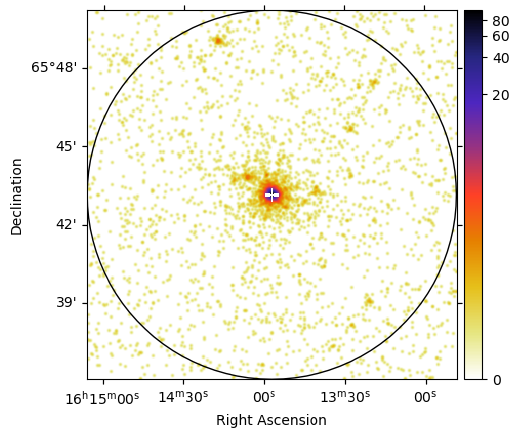

In [ ]:
ax = m.sum_over_axes().smooth(1).plot(stretch='log',cmap='CMRmap_r',add_cbar=True)
ax.scatter_coord(SkyCoord.from_name(obj_name),marker='+',color='white',s=100,zorder=100, label=obj_name)
                    
s1 = SphericalCircle((obj_pos.ra ,obj_pos.dec), radius * u.arcsec,
                     edgecolor='black', facecolor='none',
                     transform=ax.get_transform('icrs'))

ax.add_patch(s1)

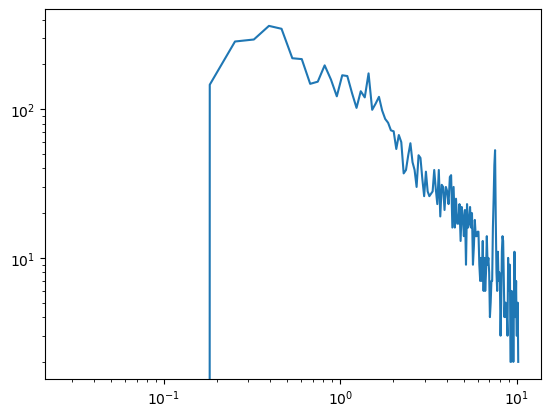

In [ ]:
E_cen = m.geom.axes[0].center
plt.loglog(E_cen, m.data.sum(axis=(1,2)) )

In [ ]:
outfile = out_path / f'{label}_Cube_{m.data.shape[2]}pix_XYrebin{XYrebin}_Erebin{Erebin}.fits'

m.write(outfile,overwrite=True)
# compress(outfile)
print(outfile)
print("Erebin = ", Erebin)
print("ETrebin = ", ETrebin)
print("XYrebin = ", XYrebin)
print("pix = ", m.data.shape[2])
pix = m.data.shape[2]

E_cen=None ;RAc=None ; DEC_=None ;DECc=None ; E_=None ; Ec=None ; TOA_=None ; TOAc=None ; mask=None #freeing memory


/Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/output/3D-XRT_Mrk876_r425_00050300004_Cube_361pix_XYrebin1_Erebin7.fits
Erebin =  7
ETrebin =  11
XYrebin =  1
pix =  361


In [ ]:
RA, DEC, E, TOA, radec, energy, rmf, rmffile, matrix_hdu, old_data, old_header, new_matrix_hdu, mod_rmf_file, rmf_preslice, edisp, m, ax = None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None, None

## 2. Load Counts Cube

Can start here if coounts map already created

The counts cube was filled directly from the Swift-XRT cleaned event file, binning each event by RA, Dec sky position (from detector $X, Y$ coordinates) and energy channel (PI x 10) into a \texttt{WcsNDMap}$(X_{\rm reco}, Y_{\rm reco}, E_{\rm reco})$.

In [ ]:
# get cube file from Create-cube-gammapy.ipynb

Erebin =  7
ETrebin =  11
XYrebin =  1
pix =  361

cubefile = out_path / f'{label}_Cube_{pix}pix_XYrebin{XYrebin}_Erebin{Erebin}.fits'

In [ ]:
cube_data=Map.read(cubefile,map_type='wcs')
cube_data.data = np.array(cube_data.data,dtype='float64')

livetime=cube_data.meta['EXPOSURE']*u.s
print(livetime)

25457.32762715322 s


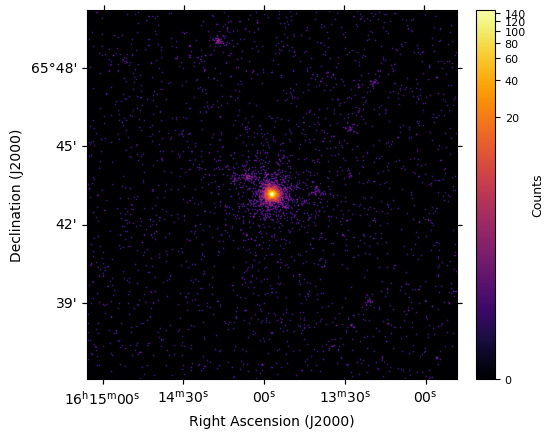

In [ ]:
fig = plt.figure()

ax = cube_data.sum_over_axes().smooth(width=0.5).plot(add_cbar=False,stretch='log', cmap='inferno')

im = ax.get_images()[0]
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label(r"Counts", size=9)
cbar.ax.tick_params(labelsize=8)


ax.set_xlabel("Right Ascension (J2000)")
ax.set_ylabel("Declination (J2000)")


plt.show()

## 3. EDISP

The conversion of the Swift native format to \texttt{gammapy} format is achieved via the OGIP-compatible energy redistribution matrix (RMF). By reading in the relevant Swift-XRT RMF in \texttt{gammapy}, the reconstructed energy $E_{\rm reco}$ and true energy $E_{\rm true}$ axes required for analysis were defined from the Pulse Invariant (PI) detector channels and photon energy bins. The matrix was stored in a \texttt{gammapy} energy dispersion kernel  \texttt{EDispKernel} as a function of $E_{\rm true}$.

In [ ]:
# Loading the standard RMF (std binning) recommended by CALDB

try:
    rmf=EDispKernel.read(rmf_file) # works fine for swxpc0to12s6_20210101v016.rmf
    print("read in:", rmf_file)

except:
    mod_rmf_file = f"{evtdir}/{obslist[0]}/xrt/mine/modified_Obs_{obslist[number]}pc.rmf"
    rmf=EDispKernel.read(mod_rmf_file)
    print(mod_rmf_file)
    print("read in:", mod_rmf_file)

rmf_sliced = rmf.slice_by_idx({"energy": slice(1, -1)})
rmf_sliced = rmf_sliced.slice_by_idx({"energy_true": slice(1, -1)})
rmf = rmf_sliced

edisp=EDispKernelMap.from_edisp_kernel(rmf, geom=None)
edisp = edisp.resample_energy_axis(rmf.axes["energy"].downsample(Erebin))
edisp = edisp.resample_energy_axis(rmf.axes["energy_true"].downsample(ETrebin))
edisp.edisp_map.data = edisp.edisp_map.data / ETrebin # need to manually divide the data by ETrebin because gammapy does not do this automatically for energy true

/Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/data/reproc/00050300004/xrt/mine/modified_Obs_00050300004pc.rmf
read in: /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/data/reproc/00050300004/xrt/mine/modified_Obs_00050300004pc.rmf


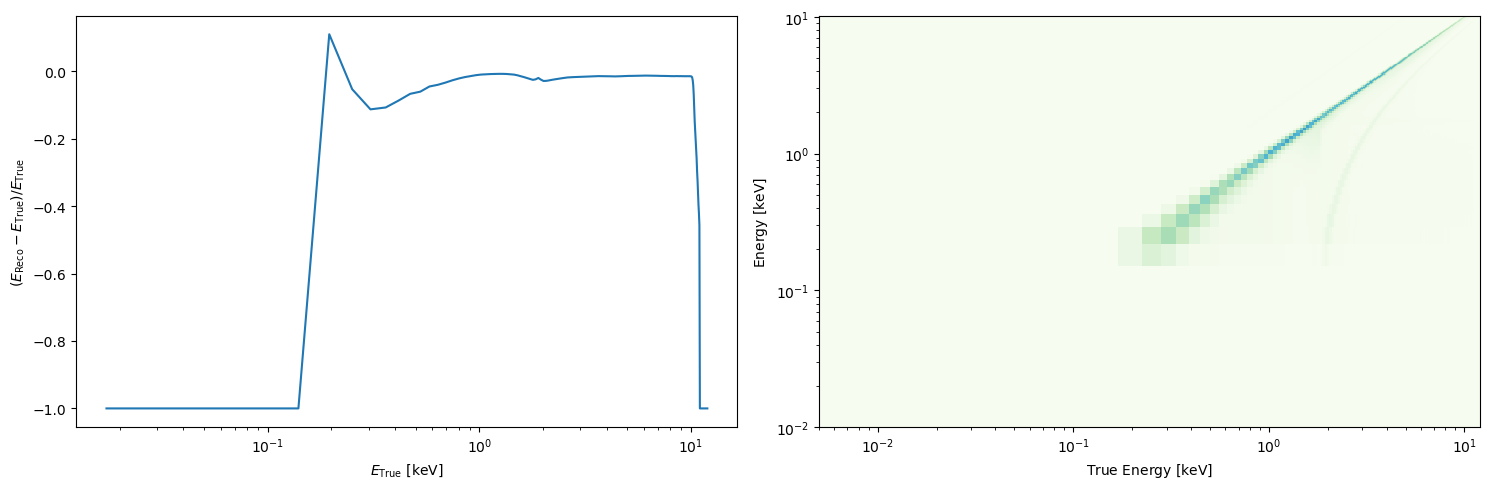

In [ ]:
edisp.peek()

## 4. Exposure Cube

This element combines both the effective area as a function of energy (ARF) and the spatial exposure information with vignetting and livetime (units of ${\rm cm}^2 \, {\rm s}$).

Contrary to the standard Swift analysis, the 3D analysis requires a full-enclosure ARF with no PSF flux correction that depend on the radius of the extraction region considered, instead considering an infinite PSF region. This is extracted with \texttt{xselect} for the spectrum of a circle encompassing the full data cube, then ran \texttt{xrtmkarf} (no exposure map, no PSF correction, extended-source flag off) to obtain the ARF. Here the ARF has already been created, with instructions on how to described in the data section (run_arfcreation.sh). 

Reading in the full-enclosure ARF with \texttt{OGIPDatasetReader} and resampling it onto a \texttt{RegionNDMap}, the effective area as a function of $E_{\rm true}$ was obtained. A 3D exposure cube $(X_{\rm true}, Y_{\rm true}, E_{\rm true})$ was populated by multiplying the 1D effective area with the 2D normalised vignetting map (available in the locally-reprocessed data products). As this vignetting is calculated for $1.5 \, {\rm keV}$, this implies that \texttt{3D-XRT} does not handle an energy-dependent representation of the vignetting, therefore this remains a limitation of the current implementation which has not been deemed critical for this study.

read in: /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/data/reproc/00050300004/xrt/mine/Obs_00050300004pc_all_602.arf


<Axes: xlabel='True Energy [$\\mathrm{keV}$]', ylabel='$\\mathrm{cm^{2}\\,s}$'>

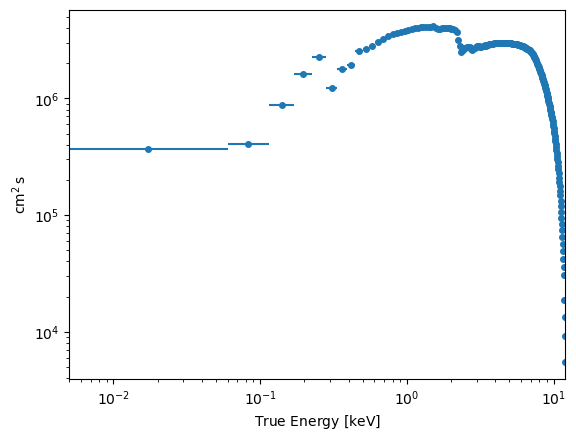

In [ ]:
# initially, read in any arf file just to get the geometry
aeff=OGIPDatasetReader.read_arf(arffile_first,livetime=livetime)
print("read in:", arffile_first)
# if inst in ['XRT']:
    # Resample datasets. Swift-XRT start their edisp from E=0 keV, 
    # we need to discard that first problematic bin, otherwise the log-space evaluation in gammapy fails.
    # also discard last to have even number of bins
aeff_sliced = aeff.slice_by_idx({"energy_true": slice(1, -1)})
aeff = aeff_sliced
aeff_resampled = aeff.downsample(ETrebin, preserve_counts=False, axis_name='energy_true')
aeff = aeff_resampled

aeff.plot()

In [ ]:
# get exposure cube from cube with data empty, then fill with data with 1D true energy effective area and 2D normalised vignetting map (stacked if multiple observations)
# this part is quite slow so if you already have the file read it in
try:
    exp_file = f"{out_path}/{label}_exposure_corr.fits"
    exposure = Map.read(exp_file)
    print("loaded in ", exp_file)

except:
    livetime_total = 0*u.s
    map_geom = cube_data.geom.to_image().to_cube(axes=[aeff.geom.axes['energy_true']])
    exposure = Map.from_geom(map_geom, unit="cm2 s")

    for nr in range(len(obslist)):

        print(nr, obslist[nr])

        if inst in ['XRT']:
            regexp='%s/%s/xrt/event/%s'%(evtdir,obs,evtfile)
        for myfile in glob.glob(regexp):
            file_evt=myfile
        hdr = fits.getheader(file_evt, extname='EVENTS')
        print("read in:", file_evt)

        livetime_new = hdr['LIVETIME']*u.s
        print("livetime:",livetime_new)

        # update aeff for each observation, as they can differ
        arffile_new=arffile_list[nr]
        aeff_new=OGIPDatasetReader.read_arf(arffile_new,livetime=livetime_new)
        print("read in:", arffile_new)
        aeff_sliced_new = aeff_new.slice_by_idx({"energy_true": slice(1, -1)})
        aeff_new = aeff_sliced_new
        aeff_resampled_new = aeff_new.downsample(ETrebin, preserve_counts=False, axis_name='energy_true')
        aeff_new = aeff_resampled_new
        
        # get vigneting from img
        if inst in ['XRT']:
            regexp_vig='%s/%s/xrt/event/%s'%(evtdir,obs,vigfile)
        for myfile_vig in glob.glob(regexp_vig):
            file_vig=myfile_vig
        vig_map = Map.read(file_vig)
        print("read in:", file_vig)
        vig_reproj = vig_map.reproject_to_geom(cube_data.geom.to_image(), preserve_counts=False, precision_factor=10)
        
        exposure.data += aeff_new.data.flatten()[:,None, None] * (vig_reproj / vig_reproj.data.max())
        livetime_total += livetime_new

    exposure.meta = {'livetime': livetime_total}
    exp_file = f"{out_path}/{label}_exposure_corr.fits"
    exposure.write(exp_file, overwrite=True)
    print("written to ", exp_file)

loaded in  /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/output/3D-XRT_Mrk876_r425_00050300004_exposure_corr.fits


<WCSAxes: >

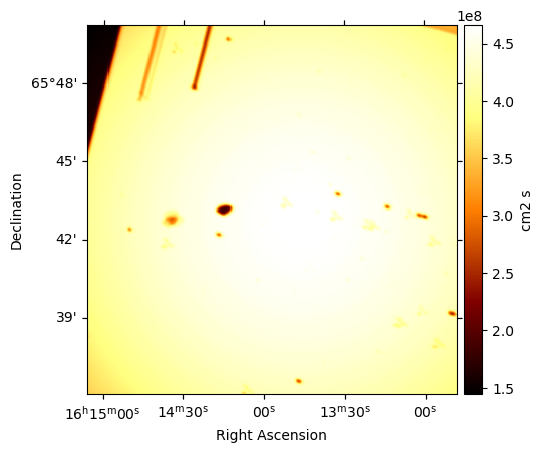

In [ ]:
exposure.sum_over_axes().smooth(width=1).plot(add_cbar=True)

## 5. PSF

The Swift-XRT PSF was evaluated following the official point spread function (PSF) of Swift-XRT was applied to all analyses. It is given by a combination of a Gaussian and a King model:
${\rm PSF}(r) = W \cdot {\rm e}^{- \frac{r^2}{2 \sigma^2}} + (1-W) \left[ 1 + \left({\frac{r}{r_{\mathrm{c}}}}\right)^2 \right]^{-\beta}$,
where $W$ is the fractional normalisation weight between the Gaussian and King components, $\sigma$ is the Gaussian width, while $r_{\mathrm{c}}$ and $\beta$ set the core width and wing profile of the King component \citep{PSFpanter_Moretti_2004SPIE.5165..232M} as a function of radius $r$. These PSF parameters and those of the redistribution matrix files are given in the CALDB Swift-XRT calibration files, documented in the release notes\footnote{\url{https://swift.gsfc.nasa.gov/caldb/docs/xrt/index.html}}.

We here evaluate the PSF function with coefficients from the CALDB PSF file (current coefficients provide an energy-independent PSF). When passed to \texttt{make\_psf\_map}, along a suitable map geometry with a radial axis ${\rm rad}$ (relative to the centre of the skymap) and $E_{\rm true}$ axis, this yielded a \texttt{PSFMap} $(X_{\rm true}, Y_{\rm true}, {\rm rad}, E_{\rm true})$, which produces a 2D PSF convolution kernel. Note that with current implementations, the PSF evolution through the field of view has only a radial dependence and no angular dependence. Asymmetric PSF are therefore not handled, even though for bright sources we can see some asymmetry in the observed point spread.

In [ ]:
filename = psffile
psf = SwiftPSF.read(filename) # will print parameters used when evaluated
print("read in:", psffile)
pointing = cube_data.geom.center_skydir # the geometry of the observed data cube ie the center of your image

# Define radial axis. Note that the name is fixed.
#this is the axis that will define the resolution on which the PSF is evaluated
#need to well sample the PSF so bin size should of a few arcsec at most
rad_axis = MapAxis.from_bounds(0.0* u.arcsec, 600 * u.arcsec, nbin=400, name="rad")

exposure_energy_true=exposure.geom.axes['energy_true'] #needs to be from the same energy_true axis !!

psf_geom = WcsGeom.create(
    skydir=pointing,
    width=(0.25, 0.25),   #this axis is the FoV dimension that will handle the offset angle variation, slightly larger than image
    binsz=0.05,         # so low resolution is ok as variation with offset is smooth, and we want to keep the map size reasonable
    axes=[rad_axis, exposure_energy_true]
)

psf_swift=make_psf_map(psf=psf, pointing=pointing, geom=psf_geom)


calling SwiftPSF.read
read in: /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/psf/swxpsf20010101v006.fits
calling SwiftPSF.evaluate_parameters
P0: 0.07469390332698822
P1 (pix): 3.1489999294281006
P1: 0.002061720231572787 deg
P2 (pix): 1.5809999704360962
P2: 0.0010351158139771885 deg
P3: 1.3049999475479126
calling SwiftPSF.evaluate_direct


In [ ]:
    # slightly modified peek function to show keV instead of TeV
    # and comment out exposure and containment radius as nothing and constant is expected
    def peek(self, figsize=(12, 10)):
        """Quick-look summary plots.

        This method creates a figure with four subplots:

        * Containment radius at center of map plot : Containment radius as a function of energy for
          containment fractions of 65% and 95%.
        * PSF at center of map plot : PSF vs radius.
        * Exposure 2D map : exposure summed over true energy
        * Containment radius map : 2D sky map of the 68% containment radius at 1 TeV

        Parameters
        ----------
        figsize : tuple, optional
            Size of figure. Default is (12, 10).
        """
        fig, axes = plt.subplots(
            ncols=2,
            nrows=1,
            subplot_kw={"projection": self.psf_map.geom.wcs},
            figsize=figsize,
            gridspec_kw={"hspace": 0.3, "wspace": 0.3},
        )

        axes = axes.flat
        axes[0].remove()
        ax0 = fig.add_subplot(2, 2, 1)
        ax0.set_title("Containment radius at center of map")
        self.plot_containment_radius_vs_energy(ax=ax0)

        axes[1].remove()
        ax1 = fig.add_subplot(2, 2, 2)
        # ax1.set_ylim(1e-4, 1e4)
        ax1.set_title("PSF at center of map")
        self.plot_psf_vs_rad(ax=ax1, energy_true=[1, 5, 10] * u.keV)

        # axes[2].set_title("Exposure")
        # if self.exposure_map is not None:
        #     self.exposure_map.reduce_over_axes().plot(ax=axes[2], add_cbar=True)
        # else:
        #     print("no psf exposure map")

        # axes[3].set_title("Containment radius at 1 keV")
        # kwargs = {self.energy_name: 1 * u.keV}
        # self.containment_radius_map(**kwargs).plot(ax=axes[3], add_cbar=True)

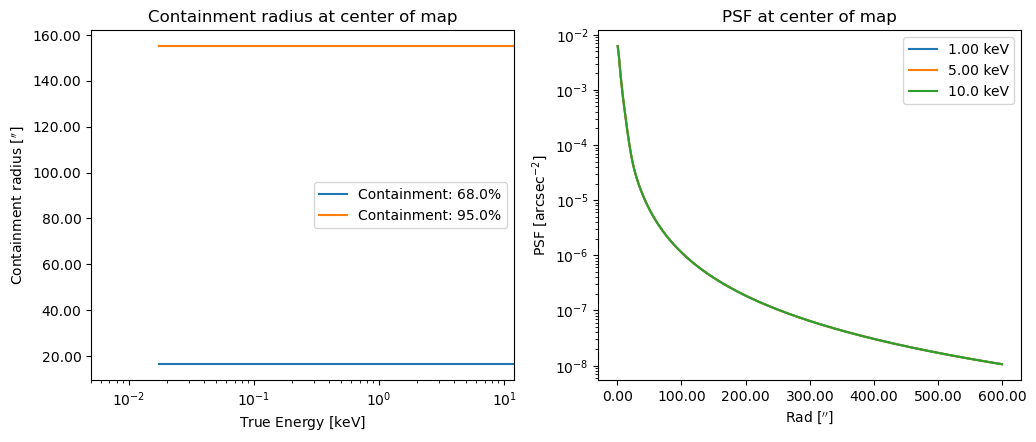

In [ ]:
peek(psf_swift)
# no energy dependence with current coefficients

<Axes: >

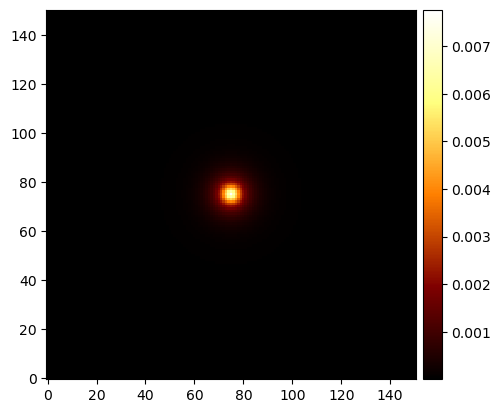

In [ ]:
# Plot example

# Create WcsGeom
kernelgeom = WcsGeom.create(width="50 arcsec",
    binsz="1 arcsec",  skydir=pointing, axes=[exposure_energy_true]
)

#psf_kernel = psfmap.get_psf_kernel(geom=psfgeom , max_radius=100*u.arcsec)
psf_kernel = psf_swift.get_psf_kernel(geom=kernelgeom, containment=0.9 )

psf_kernel.plot_kernel(energy=1*u.keV, add_cbar=True)

### Checking energy binning between data, exposure, edisp in same E_reco and E_true

In [ ]:

print('cube_data',cube_data.geom.axes['energy'])

print('edisp',edisp.edisp_map.geom.axes['energy'])
print('edisp',edisp.edisp_map.geom.axes['energy_true'])


print('exposure',exposure.geom.axes['energy_true'])

cube_data MapAxis

	name       : energy    
	unit       : 'keV'     
	nbins      : 146       
	node type  : edges     
	edges min  : 1.0e-02 keV
	edges max  : 1.0e+01 keV
	interp     : log       

edisp MapAxis

	name       : energy    
	unit       : 'keV'     
	nbins      : 146       
	node type  : edges     
	edges min  : 1.0e-02 keV
	edges max  : 1.0e+01 keV
	interp     : log       

edisp MapAxis

	name       : energy_true
	unit       : 'keV'     
	nbins      : 218       
	node type  : edges     
	edges min  : 5.0e-03 keV
	edges max  : 1.2e+01 keV
	interp     : log       

exposure MapAxis

	name       : energy_true
	unit       : 'keV'     
	nbins      : 218       
	node type  : edges     
	edges min  : 5.0e-03 keV
	edges max  : 1.2e+01 keV
	interp     : log       



## 6. Masks

Masks are applied to adjust the energy and spatial range considered by the dataset. Masks in \texttt{gammapy} are the multi-dimensional equivalent of the \texttt{ignore} command in \texttt{xspec}. A spatial mask excludes regions around bright nearby sources (and excludes the pile-up region when needed). A spectral mask restricts the fit to a given energy range.

### Mask other sources

Mark and mask undesired sources in the skymap, here from a loaded table

In [ ]:
name_in_dict = [
    "sno", "x", "y", "ra", "ra_pos", "ra_neg", 
    "dec", "dec_pos", "dec_neg", "err90", "l", "b", 
    "C", "rawrate", "rate", "rate_pos", "rate_neg", 
    "rateCF", "bgInFit", "B", "Cstat", "Cbg", "Lbg", 
    "SNR", "PSFRad", "MergeRad", "FlagName", "ImOntime", 
    "FracExp", "offaxis", "NNDist", "OKNNDist", "OLwarn", 
    "SLwarn", "CtsInFit", "detFlag", "shortFF", "usedPup", 
    "pupS", "pupl", "pupc", "puptau", "bgRateAtSrc"
]

In [ ]:
source_list = ascii.read(sources_total_file, names = name_in_dict)
print("read in:", sources_total_file)

read in: /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/data/USERPROD_282534/sourceDet/sources_total.list


In [ ]:
source_list['position'] = SkyCoord(source_list['ra'], source_list['dec'], unit="deg")
is_source = (source_list['position'].separation(obj_pos) < 1 *u.arcmin)
in_geom = cube_data.geom.to_image().contains(source_list['position'])
# can also filter to not exclude insignificant sources, but in this long observation we exclude all
# significant = (source_list['rate'] > 5e-4) # this can be adjusted based on what you want to exclude, could also be based on SNR or other parameters
area_sources = source_list[in_geom & ~is_source]
area_sources

sno,x,y,ra,ra_pos,ra_neg,dec,dec_pos,dec_neg,err90,l,b,C,rawrate,rate,rate_pos,rate_neg,rateCF,bgInFit,B,Cstat,Cbg,Lbg,SNR,PSFRad,MergeRad,FlagName,ImOntime,FracExp,offaxis,NNDist,OKNNDist,OLwarn,SLwarn,CtsInFit,detFlag,shortFF,usedPup,pupS,pupl,pupc,puptau,bgRateAtSrc,position
,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,"deg,deg"
str9,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64,str4,float64,float64,float64,float64,float64,int64,int64,float64,int64,str2,int64,float64,float64,float64,float64,float64,SkyCoord
Source_2,547.8271450575,808.7858554803,243.5709195059,0.000718320466620301,-0.000745089623060087,65.8173490346,0.0002952255,-0.0003018726,4.19398344545299,98.3663475752378,40.3030775361635,57,0.0027386516,0.0030308703,0.0004744274,-0.0004341911,1.4003638504,6.9087817826e-07,6.5306938693,167.0418893569,415.056671689,40.0,5.6647966755,12.0,10,GOOD,23318.4,0.892723747555578,7.22078524604446,150.870922253418,150.870922253418,0,0,57.0,0,OK,0,0.8741733672,45.814920826,4.4987545371,199.9982352003,6.909e-07,"243.5709195059,65.8173490346"
Source_3,575.3960917285,675.6965400566,243.526446584,0.000885601611197791,-0.00091794790023608,65.7302421082,0.0003815827,-0.0003794775,4.5461377554533,98.2734047584839,40.3569337268979,93,0.0040353319,0.0024279192,0.0005417855,-0.0005056086,1.2647467841,4.637145617e-06,48.2362823249,289.7808860412,398.7914516077,40.0,4.9594737023,12.0,10,GOOD,23318.4,0.988191371534925,2.52288608971316,32.6824380003361,68.5006290837233,0,0,93.0,0,OK,0,-1.0,-1.0,-1.0,-1.0,4.6069e-06,"243.526446584,65.7302421082"
Source_7,698.4355227636,768.0264477569,243.3302556662,0.00132255069990824,-0.00117360026213694,65.7907281948,0.0004473969,-0.0004830301,5.14674059744905,98.3906192957964,40.4035564822891,24,0.0010981944,0.0009521821,0.0003007312,-0.0002622962,1.3336940394,7.4107915813e-07,7.3515670351,105.9841240699,167.327299831,28.8232795524,3.0844467365,12.0,10,GOOD,23318.4,0.936992130463497,5.56971841164733,119.83960663428,119.83960663428,0,0,24.0,0,OK,0,-1.0,-1.0,-1.0,-1.0,7.411e-07,"243.3302556662,65.7907281948"
Source_8,642.2629016991,661.7257987798,243.4199177362,0.00130722638274312,-0.00132006583258862,65.7211401901,0.0005807367,-0.0005532478,5.52578469215545,98.2873204228583,40.4003898906535,38,0.0016341764,0.0009604982,0.0003504848,-0.0003145004,1.2542563734,1.9201497047e-06,20.1433194928,172.8764024616,219.4750585639,21.5835253987,3.0425130895,12.0,10,GOOD,23318.4,0.997201996406271,1.1177174397718,102.061257877388,102.061257877388,0,0,38.0,0,OK,0,-1.0,-1.0,-1.0,-1.0,1.9201e-06,"243.4199177362,65.7211401901"
Source_10,693.7252959888,554.5377781103,243.3381493508,0.00138333983108083,-0.00146153221278956,65.6509376597,0.0005487804,-0.0005500951,5.61219843127442,98.2231454639439,40.4610166077459,19,0.0008509385,0.0006530959,0.0002641258,-0.0002265215,1.3048695763,7.1994612834e-07,7.3291274498,88.4591508191,136.3715724852,22.2270609166,2.7753634559,12.0,10,GOOD,23318.4,0.957346832029642,4.48818049907573,131.235120080364,214.251883034181,0,0,19.0,0,OK,0,-1.0,-1.0,-1.0,-1.0,7.2e-07,"243.3381493508,65.6509376597"
Source_11,675.4383895317,722.687945175,243.3670237111,0.00129634187057654,-0.00122478053729894,65.7610541296,0.000566967,-0.0005258449,5.39766513026035,98.3469164313323,40.4027849515524,22,0.0009680084,0.0007392741,0.0002776952,-0.0002407425,1.2822574596,8.275670468e-07,8.5562012486,107.8217153646,153.7015928931,21.2315924305,2.7517273374,12.0,10,GOOD,23318.4,0.974495062568615,3.60209725842727,119.839606634287,119.839606634287,0,0,22.0,0,OK,0,-1.0,-1.0,-1.0,-1.0,8.275e-07,"243.3670237111,65.7610541296"
Source_15,457.1122491517,788.347302625,243.7157618374,0.00260224099968554,-0.00218650962421327,65.8037421355,0.0010500182,-0.000779174,8.11611142956988,98.3169390382677,40.255257850281,16,0.0008162401,0.000641874,0.0002783325,-0.0002354091,1.4872273702,6.6857361607e

In [ ]:
other_sources = [CircleSkyRegion(area_sources['position'][nr], area_sources['PSFRad'][nr]*myinst['pix_size']) for nr in range(len(area_sources['position']))]
other_sources_mask = ~cube_data.geom.region_mask(other_sources)

In [ ]:
other_sources[0]

<CircleSkyRegion(center=<SkyCoord (ICRS): (ra, dec) in deg
    (243.57091951, 65.81734903)>, radius=28.284000000000002 arcsec)>

In [ ]:
other_sources[0].radius

<Quantity 28.284 arcsec>

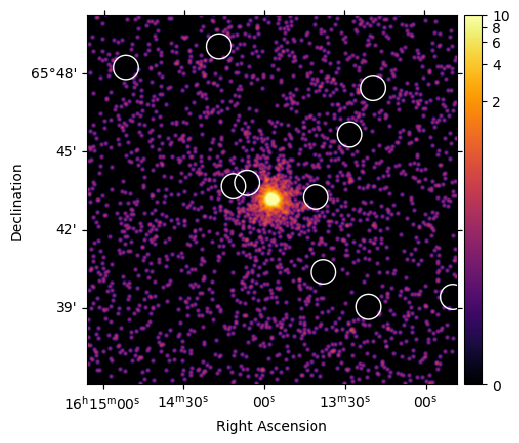

In [ ]:
# check in capped counts plot with regions excluded by other sources mask highlighted
ax = (cube_data*other_sources_mask).sum_over_axes().smooth(width=1).plot(add_cbar=True, stretch='log', cmap='inferno', vmax=10)

kwargs = {
    "edgecolor": "white",
    "facecolor": "none"
}
for nr in range(len(area_sources['position'])):
    s1 = SphericalCircle(other_sources[nr].center, other_sources[nr].radius, **kwargs, transform=ax.get_transform('icrs'))
    ax.add_patch(s1)

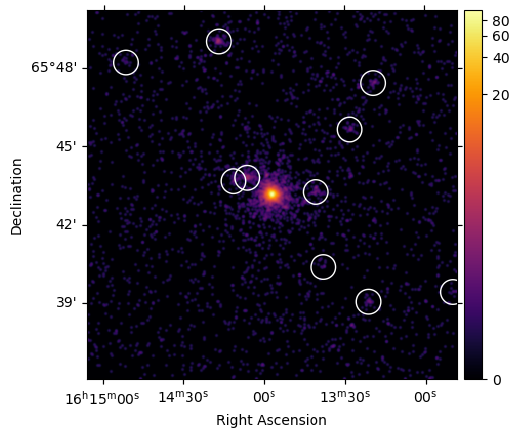

In [ ]:
# check in counts plot the regions corresponding to other sources mask
ax = cube_data.sum_over_axes().smooth(width=1).plot(add_cbar=True, stretch='log', cmap='inferno')
for nr in range(len(area_sources['position'])):
    s1 = SphericalCircle(other_sources[nr].center, other_sources[nr].radius, **kwargs, transform=ax.get_transform('icrs'))
    ax.add_patch(s1)

### Fit mask

Mask that determines which axes bins are included/excluded when fitting the models. E.g. exclude energies likely to be heavily affected by noise / components not modelled and exclude other sources not modelled.

In case of pile-up, pile-up mask in the fit mask. Not the case for this source and tutorial.

In [ ]:
# determine energy limits for fit, aligned with energy axis
# cut a lot at lower energies to limit absorption not currently considered
# 0.7099999785423279*u.keV, 9.949999809265137*u.keV
fit_energy_min, fit_energy_max = cube_data.geom.axes['energy'].edges[10], cube_data.geom.axes['energy'].edges[-5]

In [ ]:
# mask that restricts fit to circle region surrounding source
# included here to be consistent with the analysis in the 3D-XRT paper, where the fit was limited to match the regions used in the conventional 1D fit
# not strictly needed, but likely makes it a little faster and potentially avoids some distorted regions
off_out = CircleSkyRegion(obj_pos, radius*u.arcsec)
off_mask = cube_data.geom.region_mask(off_out)

In [ ]:
# define fit mask
mask_fit = Map.from_geom(cube_data.geom)
mask_fit.data = False 

# only include energies within limits 
E1, E2 = fit_energy_min, fit_energy_max 
i1,i2 =cube_data.geom.axes[0].coord_to_idx([E1,E2])
mask_fit.data[i1:i2,:,:] = True

# add spatial masks excluding regions we don't want the model fitted to
mask_fit &= other_sources_mask # logical AND
mask_fit &= off_mask # logical AND

mask_fit.plot_interactive(add_cbar=True)

interactive(children=(SelectionSlider(continuous_update=False, description='Select energy:', layout=Layout(wid…

In [ ]:
ax = (cube_data*mask_fit).smooth(width=2).plot_interactive()

interactive(children=(SelectionSlider(continuous_update=False, description='Select energy:', layout=Layout(wid…

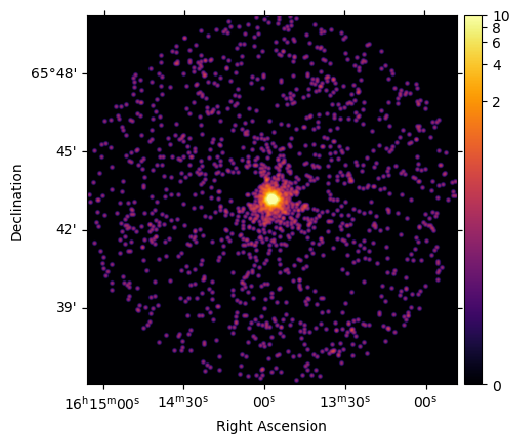

In [ ]:
ax = (cube_data*mask_fit).sum_over_axes().smooth(width=1).plot(add_cbar=True, stretch='log', cmap='inferno', vmax=10)

In [ ]:
cube_data.geom.axes['energy'].edges[5], cube_data.geom.axes['energy'].edges[-4]

(<Quantity 0.36000001 keV>, <Quantity 10.02000046 keV>)

### Safe mask

Mask that determines which axes bins are not considered in the dataset. E.g. exclude energies limited by IRF.

In [ ]:
# determine energy limits for fit, aligned with energy axis
# 0.3600000143051147*u.keV, 10.020000457763672 *u.keV
safe_energy_min, safe_energy_max = cube_data.geom.axes['energy'].edges[5], cube_data.geom.axes['energy'].edges[-4]

In [ ]:
# define safe mask
mask_safe = Map.from_geom(cube_data.geom)
mask_safe.data = False 

# only include energies within limits 
E1, E2 = safe_energy_min, safe_energy_max
i1,i2 =cube_data.geom.axes[0].coord_to_idx([E1,E2])
mask_safe.data[i1:i2,:,:] = True

# add spatial masks excluding regions we don't want the dataset to consider
mask_safe &= off_mask # logical AND

mask_safe.plot_interactive(add_cbar=True)

interactive(children=(SelectionSlider(continuous_update=False, description='Select energy:', layout=Layout(wid…

In [ ]:
cube_data.data

array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0.

In [ ]:
ax = (cube_data*mask_safe).smooth(width=2).plot_interactive()

interactive(children=(SelectionSlider(continuous_update=False, description='Select energy:', layout=Layout(wid…

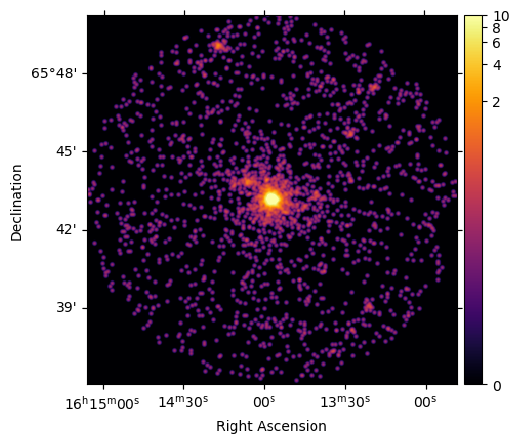

In [ ]:
ax = (cube_data*mask_safe).sum_over_axes().smooth(width=1).plot(add_cbar=True, stretch='log', cmap='inferno', vmax=10)

In [ ]:
# # plot to compare what's excluded by the masks in the radial profiles
# # it's slow, so commented out for speed

# def annulus_profile(data, geom, regions):
#     radii = []
#     sums = []

#     for reg in regions:
#         reg_profile = geom.region_mask(reg)
#         area = np.pi * (reg.outer_radius**2 - reg.inner_radius**2) / (u.arcsec**2)
#         sums.append((data * reg_profile).sum() / area)
#         mid_radius = (reg.inner_radius + reg.outer_radius) / 2
#         radii.append(mid_radius.to(u.arcsec).value)
#     return np.array(radii), np.array(sums)

# regions = make_concentric_annulus_sky_regions(
#     center=obj_pos,
#     radius_max=radius * u.arcsec,
#     nbin=int(radius / myinst['pix_size'].value),
# )

# # counts profiles for each mask case
# cases = {
#     "No mask":   (cube_data).data,
#     "Fit mask":  (cube_data * mask_fit).data,
#     "Safe mask": (cube_data * mask_safe).data,
# }

# profiles = {}
# for name, data in cases.items():
#     r, prof = annulus_profile(data, cube_data.geom, regions)
#     profiles[name] = (r, prof)

# fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 10))

# ax.set_title(f'Radial Profile {obj_name} counts')

# # Define the to_arcsec and to_pix transformations for the 2nd axis
# def to_arcsec(x):
#     return x * 2.36
# def to_pix(x):
#     return x / 2.36

# styles = {
#     "No mask":   dict(marker="o", color=tolm[1]),
#     "Fit mask":  dict(marker="^", color=tolm[7]),
#     "Safe mask": dict(marker="s", color=tolm[4]),
# }

# for name, (r, prof) in profiles.items():
#     ax.plot(r, prof, label=f"Observed counts ({name.lower()})", **styles[name])

# ax.set_ylabel(r"Surface Brightness $\mathrm{[counts\ arcsec^{-2}]}$")
# ax.legend(loc="best", frameon=True, fancybox=True, shadow=False, framealpha=0.3)
# ax.set_yscale("log")

# secax_0 = ax.secondary_xaxis('top', functions=(to_pix, to_arcsec))
# secax_0.set_xlabel(r"Radius $\mathrm{[pixels]}$", labelpad=6)
# secax_0.tick_params(axis='x', direction='in')

# secax_1 = ax.secondary_xaxis('top', functions=(to_pix, to_arcsec))
# secax_1.tick_params(axis='x', direction='in')
# secax_1.tick_params(labeltop=False)

# ax.minorticks_on()

# plt.show()

## 7. Models

Modelling of the dataset was performed with a list of \texttt{SkyModel} objects, each with spatial and spectral components. 

The point sources were modelled by \texttt{PowerLawSpectralModel} with absorption (\texttt{xspec} \texttt{TBabs}, translated per \citealt{gammapymwl_Nievas_Rosillo_2025}) with a \texttt{PointSpatialModel}. 

The diffuse background was simply modelled by a \texttt{PowerLawSpectralModel}. Concerning the instrumental background, spectral lines \citep[Nickel K$\alpha$ and K$\beta$ from the structure][]{XRT_background_Pagani2007} that are prominent in some observations were approximated with \texttt{GaussianSpectralModel}. The background models were assumed spatially constant with \texttt{ConstantSpatialModel}, and are not convolved with the PSF. An additional \texttt{PowerLawNormSpectralModel}, neither convolved with the PSF nor the exposure, was used to approximate the continuum spectral instrumental background. As the exclusion of dead pixels is usually done by convolving with the exposure cube, for the instrumental background model this exclusion was done with the 2D exposure image (included in the downloaded locally-reprocessed data, with no vignetting or ARF applied) applied as spatial template.

### TBabs model

TBabs hydrogen absorption model with nh galactic HI column density

In [ ]:
def parse_response(html_response):
    """ parses the html response and extracts the weighted total nh value """
    akey = "headers='htotw'>"
    a = html_response.index(akey) + len(akey)
    l = html_response[a:].index("</td>")
    part = html_response[a:a+l]
    if part.endswith('</sup>'):
        part = part[:-len('</sup>')]
        base, expo = part.split(' &times;10<sup>')
        return float(base) * 10**float(expo)
    else:
        return float(part)
    
def get_gal_nh_from_radec(ra, dec):
    url = "https://www.swift.ac.uk/analysis/nhtot/donhtot.php"
    """ asks swift.ac.uk for the total nh value at (ra,dec) """
    r = requests.post(url, data=dict(
        equinox=2000, Coords="%s %s" % (ra, dec),
        submit='Calculate nh')
        )
    nh = parse_response(r.text)
    return nh

def get_ra_dec(infile=None,srcname=None,src=None):
    if infile is not None:
        header = pyfits.getheader(infile)
        ra  = header['RA_OBJ']
        dec = header['DEC_OBJ']
    elif srcname is not None:
        src = SkyCoord.from_name(srcname)
        ra  = src.ra.deg
        dec = src.dec.deg
    elif src is not None:
        ra  = src.ra.deg
        dec = src.dec.deg
    else:
        raise(Exception("Need to specify either infile, srcname or a astropy SkyCorrd as src"))
        
    return(ra,dec)

def get_gal_nh(infile=None,srcname=None,src=None):
    try:
        ra,dec = get_ra_dec(infile,srcname,src)
        return get_gal_nh_from_radec(ra,dec)
    except Exception as e: 
        print(e)
        return(None)

In [ ]:
tbabs_file = f"{out_path}/tbabs_tau_factor_vs_nh_energy.ecsv"
tbabs_model_file = f"{out_path}/tbabs_tau_factor_vs_nh_energy_{obj_name}.yaml"
generate_tbabs_interp_table(tbabs_file)
nhgal = get_gal_nh(srcname=obj_name)
hyd_absorpt = get_tbabs_template_model(nh=nhgal, tbabsfile=tbabs_file, freeze=True, outfile=tbabs_model_file)
print("wrote to:", tbabs_model_file)
print(hyd_absorpt)

/Users/tarnesen/miniforge3/envs/gammapy-dev-mwl-x/lib/python3.12/site-packages/sherpa/astro/xspec/__init__.py:1576: FutureWarning: calc() requires pars,lo,hi arguments, sent 2 arguments
  warnings.warn(emsg, FutureWarning)
/Users/tarnesen/gammapy-mwl/gammapy_mwl/models/hydrogen.py:48: RuntimeWarning: divide by zero encountered in log
  tau = -np.log(wrapped_model(10**en_array * u.keV))


tbvabs Version 2.3
Cosmic absorption with grains and H2, modified from
Wilms, Allen, & McCray, 2000, ApJ 542, 914-924
Questions: Joern Wilms
joern.wilms@sternwarte.uni-erlangen.de
joern.wilms@fau.de

http://pulsar.sternwarte.uni-erlangen.de/wilms/research/tbabs/

PLEASE NOTICE:
To get the model described by the above paper
you will also have to set the abundances:
   abund wilm

Note that this routine ignores the current cross section setting
as it always HAS to use the Verner cross sections as a baseline.
wrote to: /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/output/tbabs_tau_factor_vs_nh_energy_Mrk876.yaml
TemplateNDSpectralModel

type name   value    unit   error      min       max    frozen link prior
---- ---- ---------- ---- --------- --------- --------- ------ ---- -----
       nh 2.6200e+20 cm-2 0.000e+00 1.000e+18 3.162e+24   True           


### Exposure template for instrumental background model

As the exclusion of dead pixels is usually done by convolving with the exposure cube, for the instrumental background model this exclusion was instead done with the 2D exposure image (included in the downloaded locally-reprocessed data, with no vignetting or ARF applied) applied as spatial template.

In [ ]:
# energy = energy_axis.edges
# y_unit="1/keV"
# values = u.Quantity([1] * (len(energy)), y_unit) 

# # Sort energy and reorder values accordingly
# sort_indices = np.argsort(energy)
# energy = energy[sort_indices]
# values = values[sort_indices]

# template = TemplateSpectralModel(energy=energy, values=values)
# # energy, values
# template

read in: /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/output/3D-XRT_Mrk876_r425_00050300004_ex_map.fits


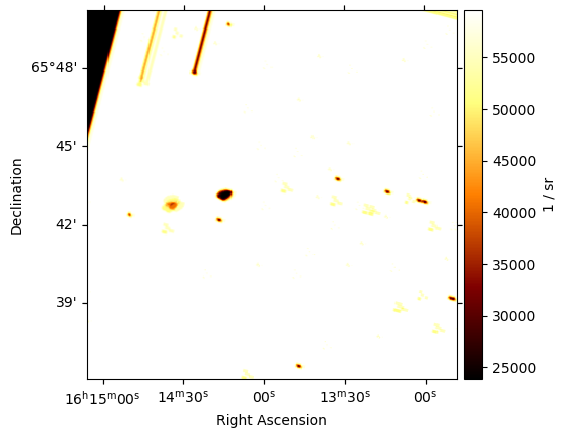

In [ ]:
try:
    ex_file = f"{out_path}/{label}_ex_map.fits"
    template_ex = Map.read(ex_file)
    print("read in:", ex_file)
    ex_model = TemplateSpatialModel(template_ex, filename=ex_file)
    ex_model.plot(add_cbar=True)
except:
    for nr in range(len(obslist)):
        if inst in ['XRT']:
            regexp_ex='%s/%s/xrt/event/%s'%(evtdir,obs,exfile)
        for myfile_ex in glob.glob(regexp_ex):
            file_ex=myfile_ex
        ex_map = Map.read(file_ex)
        print("read in:", file_ex)
        if nr == 0:
            ex_reproj = ex_map.reproject_to_geom(cube_data.geom.to_image(), preserve_counts=False, precision_factor=10)
        else:
            ex_reproj += ex_map.reproject_to_geom(cube_data.geom.to_image(), preserve_counts=False, precision_factor=10)
        print(ex_reproj.geom)
    template_ex = ex_reproj.copy(unit="sr^-1") / ex_reproj.data.max()
    template_ex.data = template_ex.data / template_ex.data.max()
    print(template_ex)
    ex_file = f"{out_path}/{label}_ex_map.fits"
    template_ex.write(ex_file, overwrite=True)

    ex_model = TemplateSpatialModel(template_ex, filename=ex_file)
    print("wrote to:", ex_file)
    ex_model.plot(add_cbar=True)

In [ ]:
# template to correct units for instrumental background model PowerLawNormSpectralModel to not be convolved with exposure
energy = edisp.edisp_map.geom.axes['energy'].edges
y_unit="1/keV"
values = u.Quantity([1] * (len(energy)), y_unit) 
template = TemplateSpectralModel(energy=energy, values=values)

### Skymodel (all models)

Models

Component 0: SkyModel

  Name                      : Mrk876
  Datasets names            : None
  Spectral model type       : CompoundSpectralModel
  Spatial  model type       : PointSpatialModel
  Temporal model type       : 
  Parameters:
    index                         :      1.500   +/-    0.00             
    amplitude                     :   5.00e-04   +/- 0.0e+00 1 / (keV s cm2)
    reference             (frozen):      1.000       keV         
    nh                    (frozen): 262000000000000000000.000      1 / cm2     
    lon_0                 (frozen):    243.488       deg         
    lat_0                 (frozen):     65.719       deg         

Component 1: SkyModel

  Name                      : bkg
  Datasets names            : None
  Spectral model type       : PowerLawSpectralModel
  Spatial  model type       : ConstantSpatialModel
  Temporal model type       : 
  Parameters:
    index                         :      2.000   +/-    0.00             
    ampl

/Users/tarnesen/gammapy_dev/gammapy/gammapy/utils/interpolation.py:215: RuntimeWarning: overflow encountered in exp
  output = np.exp(values)
/Users/tarnesen/gammapy_dev/gammapy/gammapy/modeling/models/spectral.py:649: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  ax.plot(energy.center, flux.quantity[:, 0, 0], **kwargs)


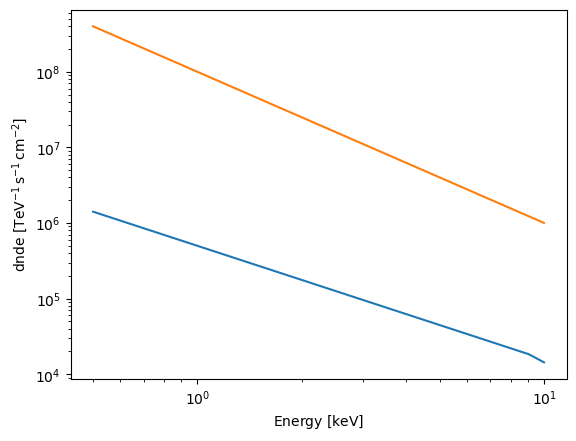

In [ ]:
# instrumental background model

inst_pow = SkyModel(
        spatial_model=ex_model,
        spectral_model = template * PowerLawNormSpectralModel(tilt=-1, norm=1e0, reference="1 keV"),
        name="inst POW",
        apply_irf={"psf": False, "exposure": False, "edisp": True},
    )
inst_pow.parameters['tilt'].min  = -10
inst_pow.parameters['tilt'].max  = 5
inst_pow.parameters['norm'].min  = 0
inst_pow.parameters['norm'].max  = 1e10


# background spectral lines (diff HE photons interact instrument structure and give Nickel K$\alpha$ and K$\beta$ lines), are either gone or negligible in some observations
Kalpha = GaussianSpectralModel(
            amplitude="1e-1 cm-2 s-1", mean=7.48 * u.keV, sigma=0.01 * u.keV
        )
Kbeta = GaussianSpectralModel(
            amplitude="1e-1 cm-2 s-1", mean=8.26 * u.keV, sigma=0.01 * u.keV
        )
nickel = SkyModel(
        spatial_model=ConstantSpatialModel(),
        spectral_model= (Kalpha+Kbeta),
        name="nickel",
        apply_irf={"psf": False, "exposure": True, "edisp": True},
    )
nickel.spectral_model.model1.parameters['amplitude'].min = 0
nickel.spectral_model.model1.parameters['amplitude'].max = 1e3
nickel.spectral_model.model2.parameters['amplitude'].min = 0
nickel.spectral_model.model2.parameters['amplitude'].max = 1e3


# diffuse bkg model
spatial_model = ConstantSpatialModel()
spectral_model = PowerLawSpectralModel(reference="1 keV")
bkg = SkyModel(spatial_model=spatial_model, spectral_model=spectral_model, name='bkg', apply_irf={"psf": False, "exposure": True, "edisp": True})
bkg.parameters['amplitude'].value = 1.e-1
bkg.parameters['amplitude'].unit = "cm-2 s-1 keV-1"
bkg.parameters['amplitude'].min  = 1e-10
bkg.parameters['amplitude'].max  = 1e6
bkg.parameters['index'].min  = 0.1
bkg.parameters['index'].max  = 5.0


# point source model
spatial_model = PointSpatialModel(lon_0=obj_pos.ra, lat_0=obj_pos.dec, frame='icrs') # with PSF
spectral_model = PowerLawSpectralModel(index=1.5, amplitude="1.e-4 cm-2 s-1 keV-1", reference="1 keV")*hyd_absorpt
mrk = SkyModel(spatial_model=spatial_model, spectral_model=spectral_model,name=obj_name)
mrk.parameters['index'].value = 1.5
mrk.parameters['amplitude'].value = 5.e-4
mrk.parameters['amplitude'].min  = 1e-9
mrk.parameters['amplitude'].max  = 1e6
mrk.parameters['index'].min  = 0.1
mrk.parameters['index'].max  = 5.0
mrk.parameters['lon_0'].frozen = True
mrk.parameters['lat_0'].frozen = True



sky_model =  mrk + bkg + nickel + inst_pow

print(sky_model)


for n in sky_model.names[:2]:
   sky_model[n].spectral_model.plot(energy_bounds=[0.5, 10] * u.keV, n_points=1000)

## 8. Dataset setup

In [ ]:
# GTIs neither needed nor included in 3D-XRT analysis paper
GTI_list = []
for obs in obslist:
    if inst in ['XRT']:
        regexp='%s/%s/xrt/event/%s'%(evtdir,obs,evtfile)
    for myfile in glob.glob(regexp):
        file_evt=myfile
    GTI = GTI.read(file_evt)
    print(obs, GTI)
    GTI_list.append(GTI)

GTI_final = GTI.from_stack(GTI_list)
print(GTI_final)

00050300004 GTI info:
- Number of GTIs: 31
- Duration: 25559.416200071573 s
- Start: 131414699.05276342 s MET
- Start: 2005-03-02T00:06:03.237 (time standard: TT)
- Stop: 131500780.65833166 s MET
- Stop: 2005-03-03T00:00:44.842 (time standard: TT)

GTI info:
- Number of GTIs: 31
- Duration: 25559.416200071573 s
- Start: 163037163.2367634 s MET
- Start: 2005-03-02T00:06:03.237 (time standard: TT)
- Stop: 163123244.84233165 s MET
- Stop: 2005-03-03T00:00:44.842 (time standard: TT)



In [ ]:
# set up dataset

dataset = MapDataset(
    models=sky_model,
    counts=cube_data,
    exposure=exposure,
    edisp=edisp,
    psf=psf_swift,
    mask_fit=mask_fit,
    mask_safe=mask_safe,
    background=None, # we don't have a dataset background, background is instead estimated as part of the models
    name=obj_name,
    gti=GTI_final # can comment out
)

%time
dataset.reset_data_cache

CPU times: user 2 μs, sys: 1e+03 ns, total: 3 μs
Wall time: 3.1 μs


<bound method MapDataset.reset_data_cache of <gammapy.datasets.map.MapDataset object at 0x70e66b0bc0>>

In [ ]:
# freeze all parameters we don't want free
for param in dataset.models.parameters:
    param.frozen = True
    
dataset.models[obj_name].spectral_model.parameters['amplitude'].frozen = False
dataset.models[obj_name].spectral_model.parameters['index'].frozen = False
dataset.models['bkg'].spectral_model.parameters['amplitude'].frozen = False
dataset.models['bkg'].spectral_model.parameters['index'].frozen = False
dataset.models['nickel'].spectral_model.model1.parameters['amplitude'].frozen = False
dataset.models['nickel'].spectral_model.model2.parameters['amplitude'].frozen = False
dataset.models['inst POW'].spectral_model.parameters['norm'].frozen = False
dataset.models['inst POW'].spectral_model.parameters['tilt'].frozen = False

In [ ]:
# # in case you want to save and have a ready setup dataset

# dataset.write(
#     filename=out_path /f"swift_xrt_{label}_initial_datasets.yaml",
#     overwrite=True,
# )

# models = dataset.models.copy()
# models

# models.write(
#     out_path /f"swift_xrt_{label}_initial_models.yaml",
#     overwrite=True,
# )

In [ ]:
def plot_data_model(dataset,comp=True):

    spec_signal=(dataset.npred_signal()*dataset.mask_fit).data.sum(axis=(1,2))
    spec_obs=(dataset.counts*dataset.mask_fit).data.sum(axis=(1,2))
    spec_npred=spec_signal
    e=(dataset.counts*dataset.mask_fit).geom.axes[0].center

    spec_signal_unmasked=dataset.npred_signal().data.sum(axis=(1,2))    
    spec_obs_unmasked=(dataset.counts).data.sum(axis=(1,2))
    spec_npred_unmasked=spec_signal_unmasked
    e_unmasked=dataset.counts.geom.axes[0].center

    spec_resid=(spec_obs-spec_npred)/np.sqrt(spec_npred)


    fig, ax1 = plt.subplots(1, 1, figsize=(9,6))
    L=0.125

    ax1.loglog(e_unmasked,spec_obs_unmasked,color='purple',label='Nobs',marker='o',ls='None')
    ax1.loglog(e_unmasked,spec_npred_unmasked,color='grey',label='Npred')

    ax1.loglog(e,spec_obs,color='blue',label='Nobs (masked)',marker='o',ls='None')
    ax1.loglog(e,spec_npred,color='black',label='Npred (masked)')

    if comp:
        for i,mod in enumerate(dataset.models):
            if type(mod) == SkyModel:
                dataset_ = MapDataset(
                    models=mod,
                    counts=dataset.counts,
                    exposure=dataset.exposure,
                    edisp=dataset.edisp,
                    psf=dataset.psf,
                    mask_safe=dataset.mask_safe,
                    mask_fit=dataset.mask_fit,
                    )
                npred_comp = dataset_.npred()
                spec_npred_comp = npred_comp.data.sum(axis=(1,2))
                ax1.loglog(e,spec_npred_comp,ls='--',label=mod.name)
    ax1.set_xlabel('Energy (TeV)')
    ax1.set_ylabel('Counts')

    ax1.set_xlim(0.3,11)
    ax1.set_title(f'{obj_name} Models')
    plt.legend()

    ax2=fig.add_axes((L,-.15,0.775,.2), sharex=ax1)

    ax2.plot(e,spec_resid,
                 marker='.',lw=0.8,label='residuals')

    ax2.set_xscale('log')    
    ax2.axhline(0, color='k', lw=1, ls='--')
    ax2.set_ylabel('(data-model)/sqrt(model)')
    ax2.set_xlabel('Energy (TeV)')
    ax2.set_xlim(0.3,11)

# plot first guess
plot_data_model(dataset, comp=True)  

In [ ]:
%time
dataset.npred().data.sum()

In [ ]:
ax = (cube_data*mask_fit).sum_over_axes().smooth(width=1).plot(add_cbar=True,stretch='log')

In [ ]:
ax = (dataset.npred()*mask_fit).sum_over_axes().smooth(width=1).plot(add_cbar=True,stretch='log')

In [ ]:
dataset.peek()

In [ ]:
dataset

## 9. Initial fit

In [ ]:
# make sure the parameters are correctly frozen
for param in dataset.models.parameters:
    param.frozen = True
    
dataset.models[obj_name].spectral_model.parameters['amplitude'].frozen = False
dataset.models[obj_name].spectral_model.parameters['index'].frozen = False
dataset.models['bkg'].spectral_model.parameters['amplitude'].frozen = False
dataset.models['bkg'].spectral_model.parameters['index'].frozen = False
dataset.models['nickel'].spectral_model.model1.parameters['amplitude'].frozen = False
dataset.models['nickel'].spectral_model.model2.parameters['amplitude'].frozen = False
dataset.models['inst POW'].spectral_model.parameters['norm'].frozen = False
dataset.models['inst POW'].spectral_model.parameters['tilt'].frozen = False

In [ ]:
%%time
pre_fit = Fit(optimize_opts={"print_level": 2, "tol": 1, "strategy": 1, 'migrad_opts':{'ncall':5000, 'iterate': 3}})
pre_result = pre_fit.optimize(datasets=[dataset])

In [ ]:
pre_result

In [ ]:
# check looks ok, no limit issues
pre_result.minuit

In [ ]:
# check that parameter fits are good (look like parabolas)
total_stat = pre_result.total_stat
models = list(sky_model)  # Use all available models dynamically
ncols = max(len(m.parameters.free_parameters) for m in models) if models else 1
nrows = len(models)  # Dynamic row count based on number of models

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 8), squeeze=False)

for i, model in enumerate(models):
    for j, par in enumerate(model.parameters.free_parameters):
        par.scan_n_values = 17
        idx = model.parameters.index(par)
        name = model.parameters_unique_names[idx]
        profile = pre_fit.stat_profile(datasets=dataset, parameter=par)

        ax = axes[i, j]
        ax.plot(profile[f"{model.name}.{name}_scan"], profile["stat_scan"] - total_stat)
        ax.set_xlabel(f"{par.name} [{par.unit}]")
        ax.set_ylabel("Delta TS")
        ax.set_title(f"{model.name}: {name}\n{par.value:.1e} ± {par.error:.1e}")

# Turn off any unused axes
for ax in axes.flat:
    if not ax.lines:
        ax.axis("off")

plt.tight_layout()

plt.show()

In [ ]:
dataset.peek()

In [ ]:
plot_data_model(dataset, comp=True)  

In [ ]:
dataset

In [ ]:
# check source flux
dataset.models[obj_name].spectral_model.energy_flux_error(fit_energy_min, fit_energy_max).to('erg cm-2 s-1')

## Optional: Position fit

It is also possible to attempt to improve the analysis by also fitting the position, e.g. by freezing all spectral parameters and leave the source spatial parameters free to vary (limits are recommended).

This has not been tested a lot, and was not done in the 3D-XRT paper.

In [ ]:
# pos_search = (3*myinst['pix_size']).to(u.deg).value
# pos_search

In [ ]:
# for param in dataset.models.parameters:
#     param.frozen = True

# dataset.models[obj_name].spatial_model.parameters['lon_0'].frozen = False
# dataset.models[obj_name].spatial_model.parameters['lat_0'].frozen = False

# dataset.models[obj_name].spatial_model.parameters['lon_0'].min = obj_pos.ra.deg - pos_search
# dataset.models[obj_name].spatial_model.parameters['lon_0'].max = obj_pos.ra.deg + pos_search
# dataset.models[obj_name].spatial_model.parameters['lat_0'].min = obj_pos.dec.deg - pos_search
# dataset.models[obj_name].spatial_model.parameters['lat_0'].max = obj_pos.dec.deg + pos_search

In [ ]:
# %%time
# pos_fit = Fit(optimize_opts={"print_level": 2})
# pos_result = pos_fit.optimize(datasets=[dataset])

In [ ]:
# print("shifted coord by:")
# print("RA:", (dataset.models[obj_name].spatial_model.parameters['lon_0'].value * u.deg).to(u.arcsec) -  obj_pos.ra.arcsec*u.arcsec)
# print("Dec:", (dataset.models[obj_name].spatial_model.parameters['lat_0'].value * u.deg).to(u.arcsec) -  obj_pos.dec.arcsec*u.arcsec)
# print("new pos:", dataset.models[obj_name].spatial_model)

## 10. Final fit

In [ ]:
# make sure the parameters are correctly frozen
for param in dataset.models.parameters:
    param.frozen = True
    
dataset.models[obj_name].spectral_model.parameters['amplitude'].frozen = False
dataset.models[obj_name].spectral_model.parameters['index'].frozen = False
dataset.models['bkg'].spectral_model.parameters['amplitude'].frozen = False
dataset.models['bkg'].spectral_model.parameters['index'].frozen = False
dataset.models['nickel'].spectral_model.model1.parameters['amplitude'].frozen = False
dataset.models['nickel'].spectral_model.model2.parameters['amplitude'].frozen = False
dataset.models['inst POW'].spectral_model.parameters['norm'].frozen = False
dataset.models['inst POW'].spectral_model.parameters['tilt'].frozen = False


In [ ]:
%%time
fit = Fit(optimize_opts={"print_level": 2, "tol": 0.1, "strategy": 2, 'migrad_opts':{'ncall':30000, 'iterate': 10}})
result = fit.optimize(datasets=[dataset])

In [ ]:
result

In [ ]:
# check looks ok, no limit issues
result.minuit

In [ ]:
# check that parameter fits are good (look like parabolas)
total_stat = result.total_stat
models = list(sky_model)  # Use all available models dynamically
ncols = max(len(m.parameters.free_parameters) for m in models) if models else 1
nrows = len(models)  # Dynamic row count based on number of models

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 8), squeeze=False)

for i, model in enumerate(models):
    for j, par in enumerate(model.parameters.free_parameters):
        par.scan_n_values = 17
        idx = model.parameters.index(par)
        name = model.parameters_unique_names[idx]
        profile = fit.stat_profile(datasets=dataset, parameter=par)

        ax = axes[i, j]
        ax.plot(profile[f"{model.name}.{name}_scan"], profile["stat_scan"] - total_stat)
        ax.set_xlabel(f"{par.name} [{par.unit}]")
        ax.set_ylabel("Delta TS")
        ax.set_title(f"{model.name}: {name}\n{par.value:.1e} ± {par.error:.1e}")

# Turn off any unused axes
for ax in axes.flat:
    if not ax.lines:
        ax.axis("off")

plt.tight_layout()

plt.show()

In [ ]:
dataset.peek()

In [ ]:
plot_data_model(dataset, comp=True)

In [ ]:
dataset

In [ ]:
# check source flux
dataset.models[obj_name].spectral_model.energy_flux_error(fit_energy_min, fit_energy_max).to('erg cm-2 s-1')

## 11. Plots

In [ ]:
# plot residual
dataset.plot_residuals()

In [ ]:
# residuals map
dataset.residuals(method="diff").sum_over_axes().smooth(width=1).plot(add_cbar=True,stretch='linear', cmap='twilight_shifted')

In [ ]:
dataset.counts.sum_over_axes().smooth(width=1).plot(add_cbar=True,stretch='log', cmap='inferno')

In [ ]:
dataset.npred().sum_over_axes().smooth(width=1).plot(add_cbar=True,stretch='log', cmap='inferno')

In [ ]:
def annulus_profile(data, geom, regions):
    radii = []
    sums = []

    for reg in regions:
        reg_profile = geom.region_mask(reg)
        area = np.pi * (reg.outer_radius**2 - reg.inner_radius**2) / (u.arcsec**2)
        sums.append((data * reg_profile).sum() / area)
        mid_radius = (reg.inner_radius + reg.outer_radius) / 2
        radii.append(mid_radius.to(u.arcsec).value)
    return np.array(radii), np.array(sums)

In [ ]:
def get_rad_profiles(counts, npred, mask_applied=None, radius_max=radius*u.arcsec, nbin=radius/myinst['pix_size']):

    regions = make_concentric_annulus_sky_regions(
        center=obj_pos,
        radius_max=radius_max,
        nbin=nbin,
    )

    if mask_applied is None:
        counts_cube = counts
        npred_cube = npred
    else:
        counts_cube = (counts*mask_applied)
        npred_cube = (npred*mask_applied)


    # counts profile
    counts_r, counts_profile = annulus_profile(
        counts_cube.data,
        counts_cube.geom,
        regions,
    )

    # npred profile
    npred_r, npred_profile = annulus_profile(
        npred_cube.data,
        counts_cube.geom,
        regions,
    )

    # # residual profile
    # residual_map = dataset.residuals(method="diff").sum_over_axes()
    # res_r, res_profile = annulus_profile(
    #     residual_map.data,
    #     residual_map.geom,
    #     regions,
    # )
    # residual profile
    residual_cube = counts - npred
    res_r, res_profile = annulus_profile(
        residual_cube.data,
        residual_cube.geom,
        regions,
    )

    return counts_r, counts_profile, npred_r, npred_profile, res_r, res_profile

In [ ]:
def plot_rad_profile(counts_r, counts_profile, npred_r, npred_profile, res_r, res_profile, plot_title=f"Radial Profile {obj_name}"):

    single_column = False
    width_mm = 88 if single_column else 120
    width_in = width_mm / 25.4
    height_in = width_in * 1.1  # Taller for 5 stacked panels

    plt.rcParams.update({
        "text.usetex": False,
        "mathtext.fontset": "stix",
        "font.family": "STIXGeneral",
        "font.size": 10,               # Increased from 9
        "axes.labelsize": 10,          # Increased from 9
        "xtick.labelsize": 9,          # Explicit tick size
        "ytick.labelsize": 9,          # Explicit tick size
        "legend.fontsize": 8,          # Explicit legend size
        "axes.linewidth": 0.8,         # Sharp lines, no thin lines
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.width": 1.0,      # Sharp, visible ticks
        "xtick.minor.width": 0.6,
        "ytick.major.width": 1.0,
        "ytick.minor.width": 0.6,
        "savefig.dpi": 300,            # 300 DPI for sharp print
        "savefig.format": "pdf",       # Vector format for quality
    })

    fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(width_in, height_in), sharex=True, height_ratios=[2*0.8*height_in, 2*0.2*height_in], gridspec_kw={'hspace': 0.02})

    axes[0].set_title(plot_title)

    # Adjusted margins: more bottom space for x-axis label clarity
    fig.subplots_adjust(top=0.93, bottom=0.16, left=0.12, right=0.97)
    # Define the to_arcsec and to_pix transformations for the 2nd axis
    def to_arcsec(x):
        return x * 2.36
    def to_pix(x):
        return x / 2.36

    axes[0].plot(counts_r, counts_profile, marker="s", color=tolm[4], label="Observed counts")
    axes[0].plot(
            counts_r,
            npred_profile,
            marker=".",
            color=gammapy_colour,
            label=f"Predicted counts",
        )

    axes[0].set_ylabel(r"Surface Brightness $\mathrm{[counts\ arcsec^{-2}]}$")
    axes[0].legend(loc="best",   frameon=True, fancybox=True, shadow=False, framealpha=0.3)
    axes[0].set_yscale("log")

    secaxes_0 = axes[0].secondary_xaxis('top', functions=(to_pix, to_arcsec))
    secaxes_0.set_xlabel(r"Radius $\mathrm{[pixels]}$",   labelpad=6)
    secaxes_0.tick_params(axis='x', direction='in',  )

    axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
    axes[1].plot(res_r, res_profile, marker=".", color=tolm[1], label=f"Residual counts")
    
    axes[1].set_ylabel("Residuals")
    axes[1].set_xlabel(r"Radius $\mathrm{[arcsec]}$")

    secaxes_1 = axes[1].secondary_xaxis('top', functions=(to_pix, to_arcsec))
    secaxes_1.tick_params(axis='x', direction='in',  )
    secaxes_1.tick_params(labeltop=False)

    axes[0].minorticks_on()
    axes[1].minorticks_on()

    plt.tight_layout()
    plt.show()

In [ ]:
counts_r, counts_profile, npred_r, npred_profile, res_r, res_profile = get_rad_profiles(dataset.counts, dataset.npred(), mask_applied=None, radius_max=200*u.arcsec, nbin=85)
plot_rad_profile(counts_r, counts_profile, npred_r, npred_profile, res_r, res_profile, plot_title=f"Radial Profile {obj_name}")

## 12. Save dataset

In [ ]:
dataset.write(
    filename=out_path /f"{label}_datasets.yaml",
    overwrite=True,
)
print("wrote to:", out_path /f"{label}_datasets.yaml")

models = dataset.models.copy()
models

models.write(
    out_path /f"{label}_models.yaml",
    overwrite=True,
)
print("wrote to:", out_path /f"{label}_models.yaml")

/Users/tarnesen/gammapy_dev/gammapy/gammapy/utils/interpolation.py:215: RuntimeWarning: overflow encountered in exp
  output = np.exp(values)
Template file already exits, and overwrite is False


wrote to: /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/output/3D-XRT_Mrk876_r425_00050300004_datasets.yaml
wrote to: /Users/tarnesen/3Dswift/notebooks/3D-XRT_tutorials/output/3D-XRT_Mrk876_r425_00050300004_models.yaml


In [ ]:
# # for reading in saved dataset

# dataset_read = MapDataset.read(filename=out_path /f"{label}_datasets.yaml")

# models_read = Models.read(out_path /f"{label}_models.yaml")

# dataset_read.models = models_read

Parameter 'value' not defined in YAML file. Using default value: 1.0 sr-1
Parameter 'value' not defined in YAML file. Using default value: 1.0 sr-1
/Users/tarnesen/gammapy_dev/gammapy/gammapy/utils/interpolation.py:215: RuntimeWarning: overflow encountered in exp
  output = np.exp(values)


## 13. Flux Points

In [ ]:
plotbins = 6

energy_edges_xrt = np.geomspace(fit_energy_min, fit_energy_max, plotbins).to('eV')

# fpe_swift = FluxPointsEstimator(
#     energy_edges=energy_edges_xrt, source=obj_name, # to get ULs add selection_optional="all", but makes it slower
# )
# fp_swift = fpe_swift.run(datasets=dataset)

In [ ]:
fig = plt.figure(figsize=(5, 5),dpi=100)

ax = dataset.models[obj_name].spectral_model.plot_error(
    [energy_edges_xrt[0],energy_edges_xrt[-1]],
    facecolor='C0',
    sed_type='e2dnde')
dataset.models[obj_name].spectral_model.plot(ax=ax, energy_bounds=[energy_edges_xrt[0],energy_edges_xrt[-1]], sed_type='e2dnde', label=f"Model {obj_name}")

fp_swift.plot(
    ax=ax, color="C0", sed_type='e2dnde',
)

ax.set_ylabel('$\mathrm{E^2\,dN/dE}$ $\mathrm{[erg\,cm^{-2}\,s^{-1}]}$')
ax.set_title(f'{obj_name} Fit swift-XRT analysis')

In [ ]:
fp_swift.write(f"{out_path}/{label}_FPs_bins_{plotbins}.fits", sed_type="e2dnde", format="gadf-sed", overwrite=True)
print("wrote to:", f"{out_path}/{label}_FPs_bins_{plotbins}.fits")